In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    if files:
        print("   Files:", len(files))

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/emmarex
/kaggle/input/datasets/emmarex/plantdisease
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Pepper__bell___Bacterial_spot
   Files: 997
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Potato___healthy
   Files: 152
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Tomato_Leaf_Mold
   Files: 952
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus
   Files: 3209
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Tomato_Bacterial_spot
   Files: 2127
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Tomato_Septoria_leaf_spot
   Files: 1771
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Tomato_healthy
   Files: 1591
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite
   Files: 1676
/kaggle/input/datasets/emmarex/plantdisease/Plant

KeyboardInterrupt: 

In [2]:
import os

DATA_DIR = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"

classes = []
total_images = 0

for class_name in sorted(os.listdir(DATA_DIR)):
    class_path = os.path.join(DATA_DIR, class_name)

    if os.path.isdir(class_path):
        classes.append(class_name)

        count = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        total_images += count

print("Number of classes:", len(classes))
print("Total images:", total_images)

print("\nClasses:")
for i, cls in enumerate(classes):
    print(i, cls)

Number of classes: 15
Total images: 20638

Classes:
0 Pepper__bell___Bacterial_spot
1 Pepper__bell___healthy
2 Potato___Early_blight
3 Potato___Late_blight
4 Potato___healthy
5 Tomato_Bacterial_spot
6 Tomato_Early_blight
7 Tomato_Late_blight
8 Tomato_Leaf_Mold
9 Tomato_Septoria_leaf_spot
10 Tomato_Spider_mites_Two_spotted_spider_mite
11 Tomato__Target_Spot
12 Tomato__Tomato_YellowLeaf__Curl_Virus
13 Tomato__Tomato_mosaic_virus
14 Tomato_healthy


,Class,Images
0,Pepper__bell___Bacterial_spot,997
1,Pepper__bell___healthy,1478
2,Potato___Early_blight,1000
3,Potato___Late_blight,1000
4,Potato___healthy,152
5,Tomato_Bacterial_spot,2127
6,Tomato_Early_blight,1000
7,Tomato_Late_blight,1909
8,Tomato_Leaf_Mold,952
9,Tomato_Septoria_leaf_spot,1771


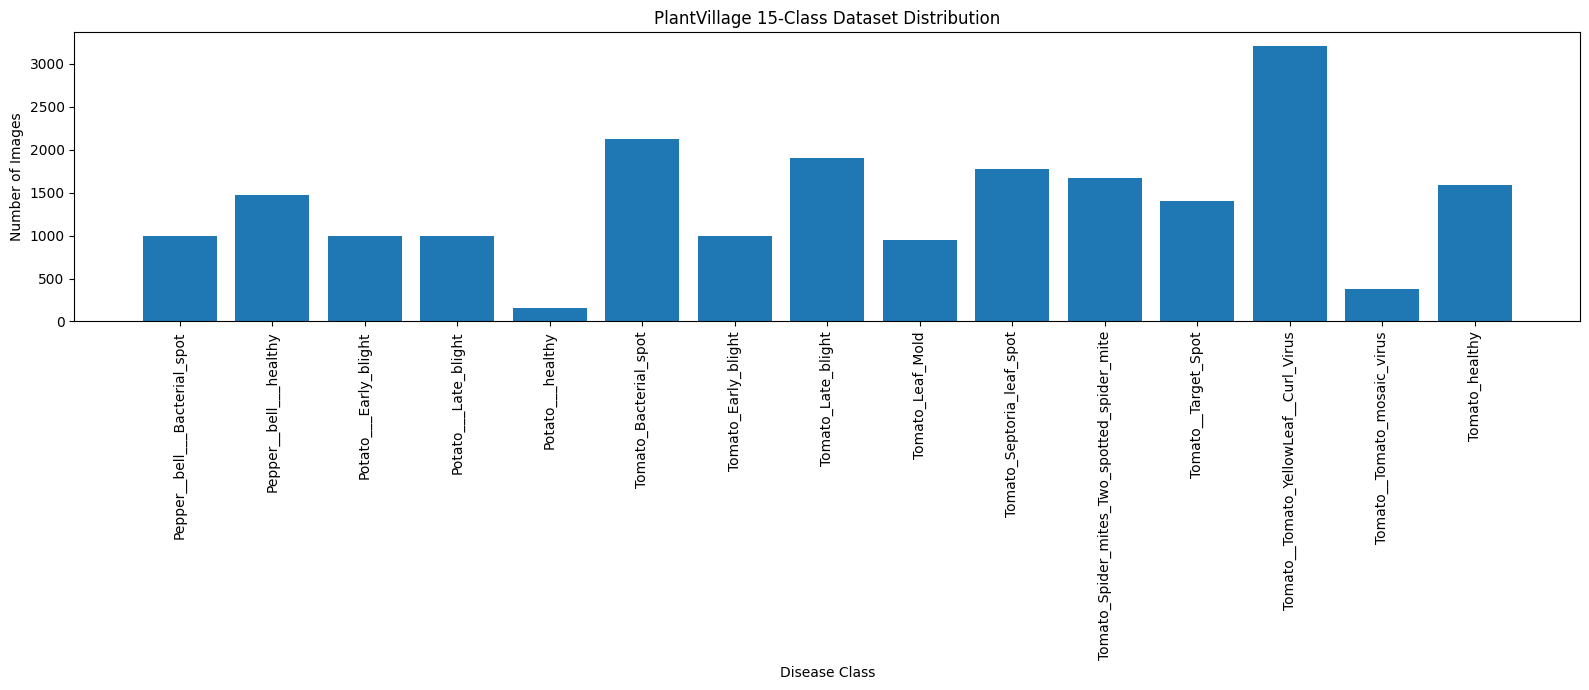

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import os

class_counts = {}

for class_name in classes:
    class_path = os.path.join(DATA_DIR, class_name)

    count = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    class_counts[class_name] = count

df_counts = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Images"]
)

display(df_counts)

plt.figure(figsize=(16, 7))
plt.bar(df_counts["Class"], df_counts["Images"])

plt.xticks(rotation=90)
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.title("PlantVillage 15-Class Dataset Distribution")

plt.tight_layout()
plt.show()

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [5]:
class_names = sorted([
    folder
    for folder in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, folder))
])

num_classes = len(class_names)

print("Number of classes:", num_classes)

print("\nClass names:")

for i, class_name in enumerate(class_names):
    print(i, ":", class_name)
    

Number of classes: 15

Class names:
0 : Pepper__bell___Bacterial_spot
1 : Pepper__bell___healthy
2 : Potato___Early_blight
3 : Potato___Late_blight
4 : Potato___healthy
5 : Tomato_Bacterial_spot
6 : Tomato_Early_blight
7 : Tomato_Late_blight
8 : Tomato_Leaf_Mold
9 : Tomato_Septoria_leaf_spot
10 : Tomato_Spider_mites_Two_spotted_spider_mite
11 : Tomato__Target_Spot
12 : Tomato__Tomato_YellowLeaf__Curl_Virus
13 : Tomato__Tomato_mosaic_virus
14 : Tomato_healthy


In [6]:
total_images = 0

class_counts = {}

for class_name in class_names:

    class_path = os.path.join(DATA_DIR, class_name)

    image_files = [
        file
        for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    count = len(image_files)

    class_counts[class_name] = count

    total_images += count

print("Total images:", total_images)

Total images: 20638


In [7]:
class_distribution = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Number of Images"]
)

display(class_distribution)

,Class,Number of Images
0,Pepper__bell___Bacterial_spot,997
1,Pepper__bell___healthy,1478
2,Potato___Early_blight,1000
3,Potato___Late_blight,1000
4,Potato___healthy,152
5,Tomato_Bacterial_spot,2127
6,Tomato_Early_blight,1000
7,Tomato_Late_blight,1909
8,Tomato_Leaf_Mold,952
9,Tomato_Septoria_leaf_spot,1771


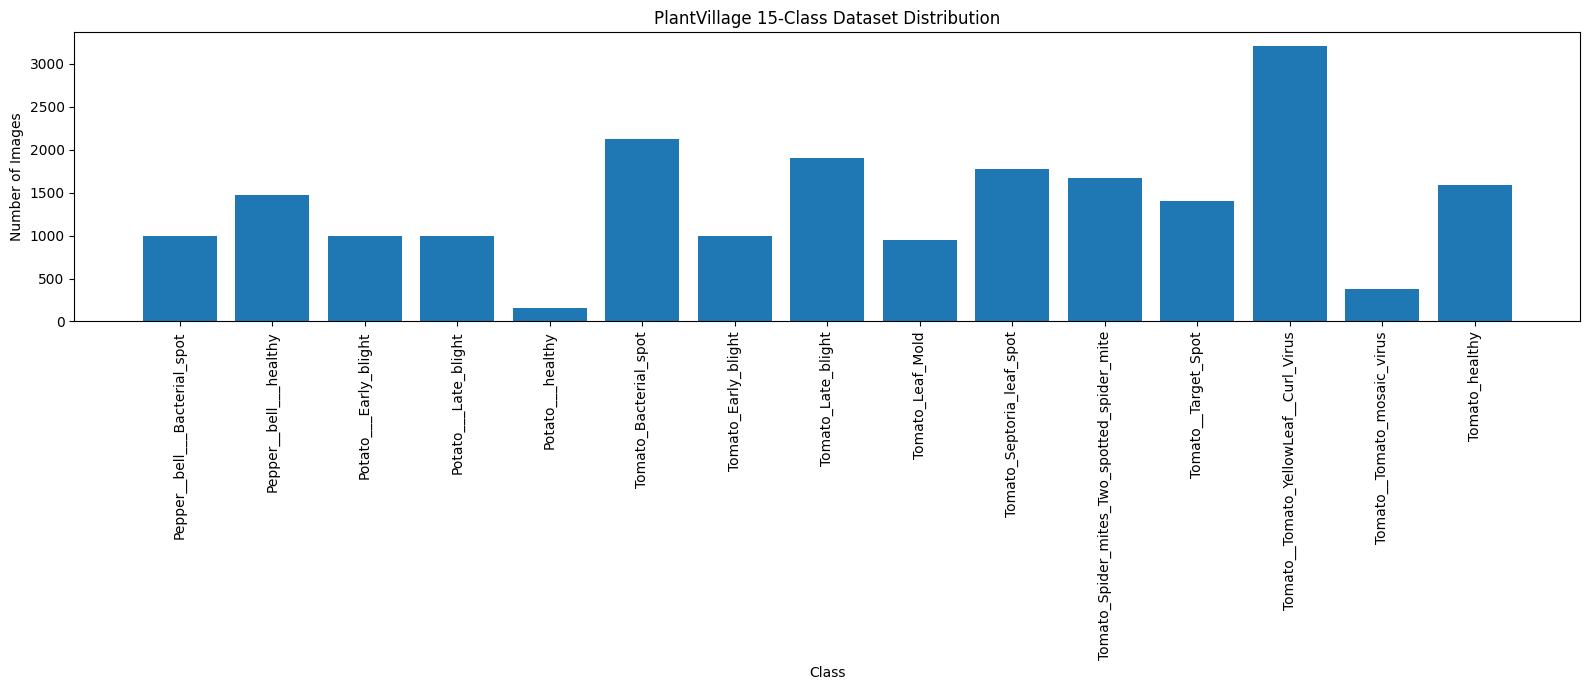

In [8]:
plt.figure(figsize=(16, 7))

plt.bar(
    class_distribution["Class"],
    class_distribution["Number of Images"]
)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("PlantVillage 15-Class Dataset Distribution")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

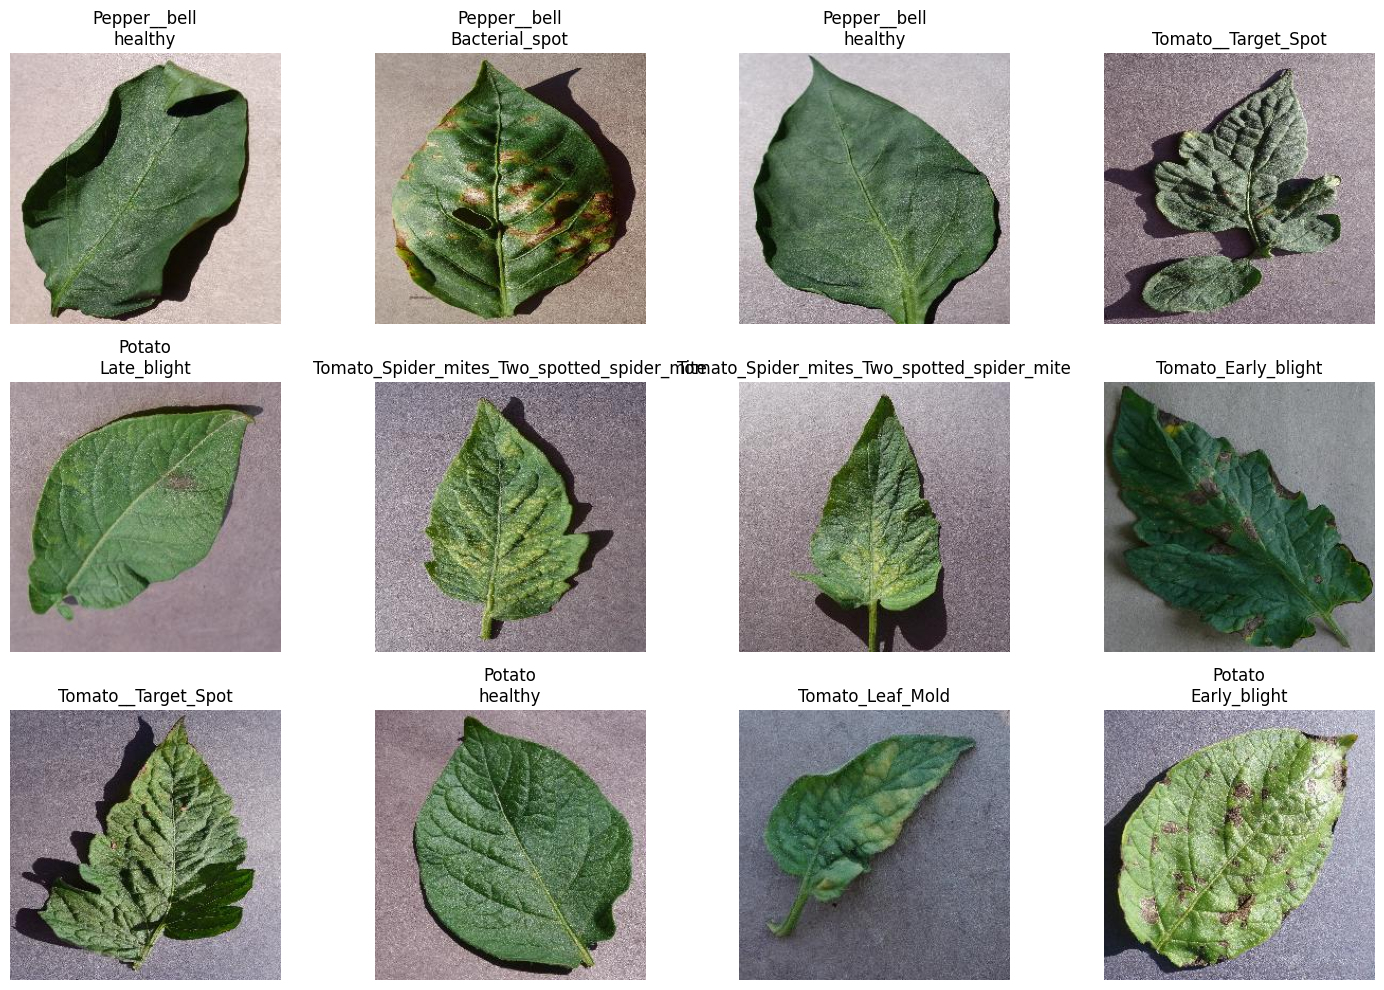

In [9]:
import random
from PIL import Image

plt.figure(figsize=(15, 10))

for i in range(12):

    # Select random class
    class_name = random.choice(class_names)

    class_path = os.path.join(DATA_DIR, class_name)

    # Get image files
    image_files = [
        file
        for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Select random image
    image_file = random.choice(image_files)

    image_path = os.path.join(class_path, image_file)

    # Open image
    image = Image.open(image_path)

    # Display
    plt.subplot(3, 4, i + 1)

    plt.imshow(image)

    plt.title(class_name.replace("___", "\n"))

    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
tf.keras.utils.image_dataset_from_directory()

TypeError: image_dataset_from_directory() missing 1 required positional argument: 'directory'

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 20638 files belonging to 15 classes.
Using 14447 files for training.


2026-10-26 17:32:58.506210: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [12]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 20638 files belonging to 15 classes.
Using 6191 files for validation.


In [13]:
val_batches = tf.data.experimental.cardinality(validation_dataset)

test_size = val_batches // 2

test_dataset = validation_dataset.take(test_size)

validation_dataset = validation_dataset.skip(test_size)

print("Dataset split completed.")

Dataset split completed.


In [14]:
train_batches = tf.data.experimental.cardinality(train_dataset).numpy()
val_batches = tf.data.experimental.cardinality(validation_dataset).numpy()
test_batches = tf.data.experimental.cardinality(test_dataset).numpy()

print("Training batches:", train_batches)
print("Validation batches:", val_batches)
print("Testing batches:", test_batches)

print("\nApproximate images:")

print("Training:", train_batches * BATCH_SIZE)
print("Validation:", val_batches * BATCH_SIZE)
print("Testing:", test_batches * BATCH_SIZE)

Training batches: 452
Validation batches: 97
Testing batches: 97

Approximate images:
Training: 14464
Validation: 3104
Testing: 3104


In [15]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)
validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

print("Input pipeline optimized.")

Input pipeline optimized.


In [16]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
])

print("Data augmentation created.")

Data augmentation created.


In [ ]:
base_model = tf.keras.applications.EfficientNetV2B0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("EfficientNetV2B0 loaded successfully.")

In [ ]:
base_model.trainable = False

print("EfficientNetV2B0 backbone frozen.")

In [ ]:
inputs = keras.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# EfficientNetV2 feature extraction
x = base_model(x, training=False)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Final classifier
outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

print("Model created successfully.")

In [ ]:
model.summary()

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully.")

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("Early stopping created.")

In [ ]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetV2B0 - Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetV2B0 - Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    test_dataset
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

In [ ]:
model.save(
    "/kaggle/working/EfficientNetV2B0_PlantVillage.keras"
)

print("Model saved successfully.")

In [ ]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Number of test images:", len(y_true))
print("Predictions generated successfully.")

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("EfficientNetV2B0 Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="macro"
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro"
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

print("===== EfficientNetV2B0 Results =====")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

In [ ]:
results = pd.DataFrame({
    "Model": ["EfficientNetV2B0"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1_Score": [f1]
})

display(results)

In [ ]:
results.to_csv(
    "/kaggle/working/EfficientNetV2B0_results.csv",
    index=False
)

print("Results saved.")

In [ ]:
print("TensorFlow version:", tf.__version__)

print(
    "ConvNeXtTiny available:",
    hasattr(keras.applications, "ConvNeXtTiny")
)

print(
    "EfficientNetV2S available:",
    hasattr(keras.applications, "EfficientNetV2S")
)

In [ ]:
# Step 2: Configure ConvNeXtTiny

IMG_SIZE = (224, 224)
NUM_CLASSES = len(class_names)

# Use a smaller batch to reduce GPU memory usage
BATCH_SIZE_NEW = 16

print("Image size:", IMG_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE_NEW)

# Check that the existing datasets are available
print("Training dataset:", train_dataset)
print("Validation dataset:", validation_dataset)
print("Test dataset:", test_dataset)

In [ ]:
# Step 3: Load ConvNeXtTiny with ImageNet pretrained weights

convnext_base = keras.applications.ConvNeXtTiny(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers for initial training
convnext_base.trainable = False

print("ConvNeXtTiny loaded successfully!")
print("Total backbone parameters:", convnext_base.count_params())
print("Trainable backbone:", convnext_base.trainable)

In [17]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 1. Load a lightweight pretrained CNN
mobile_base = keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    alpha=0.35,
    include_top=False,
    weights="imagenet"
)

mobile_base.trainable = False

# 2. Build the classifier
inputs = keras.Input(shape=(224, 224, 3))

x = layers.Resizing(160, 160)(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
x = mobile_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

mobile_model = keras.Model(inputs, outputs, name="MobileNetV2_Light")

# 3. Compile
mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 4. Save the best checkpoint
mobile_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/MobileNetV2_Light_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )
]

# 5. Short preliminary experiment
mobile_history = mobile_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=50,
    steps_per_epoch=30,
    validation_steps=10,
    callbacks=mobile_callbacks,
    verbose=1
)

# 6. Save the final in-memory model and training log
mobile_model.save("/kaggle/working/MobileNetV2_Light_final.keras")

pd.DataFrame(mobile_history.history).to_csv(
    "/kaggle/working/MobileNetV2_Light_training_log.csv",
    index=False
)

print("Preliminary experiment completed.")

2019640/2019640 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.1582 - loss: 2.8610
Epoch 1: val_loss improved from None to 1.60636, saving model to /kaggle/working/MobileNetV2_Light_best.keras

Epoch 1: finished saving model to /kaggle/working/MobileNetV2_Light_best.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 514ms/step - accuracy: 0.2781 - loss: 2.3519 - val_accuracy: 0.5719 - val_loss: 1.6064
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.5386 - loss: 1.4574
Epoch 2: val_loss improved from 1.60636 to 1.02268, saving model to /kaggle/working/MobileNetV2_Light_best.keras

Epoch 2: finished saving model to /kaggle/working/MobileNetV2_Light_best.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 291ms/step - accuracy: 0.5958 - loss: 1.3400 - val_accuracy: 0.7375 - val_loss: 1.0227
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.6592 - loss: 1.1721
Epoch 3: val_loss improved from 1.02268 to 0.86561, saving model to /kaggle

In [19]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

# Collect each batch's labels and predictions together
all_labels = []
all_predictions = []

for images, labels in test_dataset:
    probabilities = mobile_model(images, training=False).numpy()
    predictions = np.argmax(probabilities, axis=1)

    all_labels.extend(labels.numpy())
    all_predictions.extend(predictions)

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)

# Calculate consistent metrics
accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("Corrected test metrics")
print(f"Test accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro precision: {precision:.4f}")
print(f"Macro recall:    {recall:.4f}")
print(f"Macro F1-score:  {f1:.4f}")

# Save corrected results
corrected_results = pd.DataFrame([{
    "Model": "MobileNetV2_alpha_0.35",
    "Input_Size": "160x160",
    "Training_Batches_Per_Epoch": 30,
    "Validation_Batches_Per_Epoch": 10,
    "Test_Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": f1
}])

corrected_results.to_csv(
    "/kaggle/working/MobileNetV2_Light_test_results_corrected.csv",
    index=False
)

display(corrected_results)

Corrected test metrics
Test accuracy:   0.8109 (81.09%)
Macro precision: 0.8225
Macro recall:    0.7466
Macro F1-score:  0.7619


,Model,Input_Size,Training_Batches_Per_Epoch,Validation_Batches_Per_Epoch,Test_Accuracy,Macro_Precision,Macro_Recall,Macro_F1
0,MobileNetV2_alpha_0.35,160x160,30,10,0.810889,0.822523,0.746635,0.761897
